# Sentinel-2: subset and time series

Most applications need a region of interest, not a full 110 x 110 km tile. With a `subset`,
GRSdriver reads only the pixels of the region: loading is fast and light, which makes it easy to
build time series. This tutorial extracts the Étang de Berre (a coastal lagoon near Marseille,
France) from a year of Sentinel-2 images and stacks them into a datacube.

**You will learn to**

- define a region of interest and load it from an L1C product,
- save the subset into a compact netCDF file,
- select the clearest images of a series and subset them all,
- open the subsets as a datacube and plot time series.

**Data**: the Sentinel-2 L1C products of tile T31TFJ for 2022, stored in a local archive organized
as `<tile>/<year>/<month>/<day>/*.SAFE` (see the [download tutorial](sentinel2_download.ipynb)).

In [1]:
import glob
import os
import tempfile

import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pyproj import Transformer

import GRSdriver
from GRSdriver import Sentinel2Driver

print('GRSdriver', GRSdriver.__version__)

GRSdriver 2.0.0


In [2]:
def utm_projection(crs):
    """Cartopy UTM projection of a product CRS (EPSG 326xx: north, 327xx: south)."""
    epsg = crs.to_epsg()
    return ccrs.UTM(epsg % 100, southern_hemisphere=epsg // 100 == 327)

## Settings

Adapt the archive directory to your own data. The subsets are written in a temporary directory:

In [3]:
data_dir = '/data/satellite/Sentinel-2/L1C'
tile, year = '31TFJ', '2022'
resolution = 20                     # m
band_idx = list(range(13))          # all the bands, as needed by GRS

odir = os.path.join(tempfile.gettempdir(), 'grsdriver_tutorial', tile)
os.makedirs(odir, exist_ok=True)

## Region of interest

The `subset` can be any `geopandas.GeoSeries` (in any CRS): its bounding box is used. The
`SpatioTemp` helper builds a box from its center (lon, lat) and its size in meters:

In [4]:
clon, clat = 5.10, 43.47            # Étang de Berre
width, height = 28000, 24000        # m

box = GRSdriver.SpatioTemp().wktbox(clon, clat, width=width, height=height)
aoi = gpd.GeoSeries.from_wkt([box], crs=4326)
aoi.total_bounds

array([ 4.926674, 43.361859,  5.273326, 43.577877])

```{tip}
A bounding box in the CRS of the product can also be given directly, as a list:
`subset=[(xmin, ymin, xmax, ymax)]`.
```

## Subset one image

Here the image of 2022-11-20, acquired the same day as the Landsat 9 scene of the
[Landsat tutorials](GRSdriver_landsat9_TIR.ipynb):

In [5]:
image = glob.glob(os.path.join(data_dir, tile, '2022', '11', '20', '*.SAFE'))[0]

l1c = Sentinel2Driver(image, band_idx=band_idx, subset=aoi, resolution=resolution, resolution_angle=60)
l1c.load_product()
prod = l1c.prod
print(f'{prod.x.size} x {prod.y.size} pixels, {prod.nbytes / 1e6:.0f} MB in memory')

1430 x 1236 pixels, 283 MB in memory


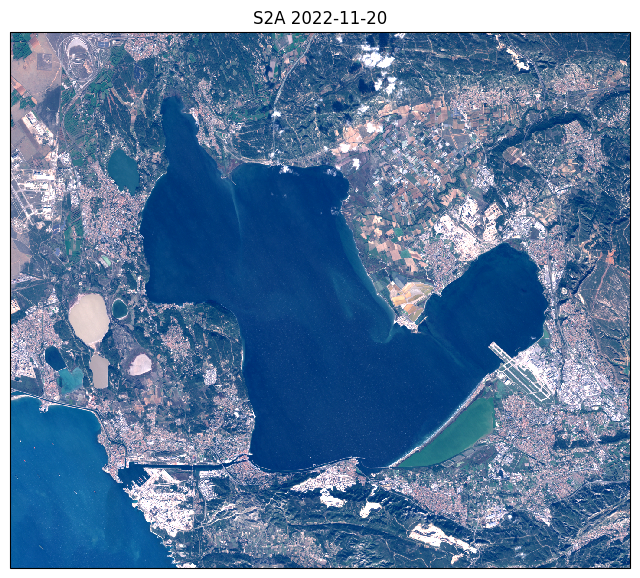

In [6]:
proj = utm_projection(prod.rio.crs)
fig = plt.figure(figsize=(8, 7))
ax = plt.axes(projection=proj)
(prod.bands.sel(wl=[665, 560, 490]) ** 0.5).plot.imshow(ax=ax, rgb='wl', robust=True, transform=proj)
ax.set_title(f'{prod.attrs["satellite"]} {prod.attrs["acquisition_date"][:10]}')
plt.show()

## Save into a compact netCDF file

The product can be written with `to_netcdf`. Encoding the variables as 16-bit integers with a
scale factor (and compressing them) divides the file size by about 4, with a precision
(5e-5 for the reflectance, 0.01 deg for the zenith angles) well below the noise of the data:

In [7]:
complevel = 5
def int16(scale_factor, add_offset=0.):
    return {'dtype': 'int16', 'scale_factor': scale_factor, 'add_offset': add_offset,
            '_FillValue': -32768, 'zlib': True, 'complevel': complevel}

encoding = {'bands': int16(5e-5, 0.3),     # reflectance from -1.34 to 1.94
            'vza': int16(0.01),
            'sza': int16(0.01),
            'raa': int16(0.1)}

def output_file(image):
    return os.path.join(odir, os.path.basename(image).replace('.SAFE', '.nc'))

prod.to_netcdf(output_file(image), encoding=encoding)
print(f'{os.path.getsize(output_file(image)) / 1e6:.1f} MB on disk')

28.3 MB on disk


## Apply to a series of images

List the products of the year, and keep the clearest one of each month (cloud cover of the
tile from the product metadata, available without loading the data):

In [8]:
images = sorted(glob.glob(os.path.join(data_dir, tile, year, '*', '*', '*.SAFE')))
# skip incomplete downloads (no metadata file)
images = [image for image in images if os.path.exists(os.path.join(image, 'MTD_MSIL1C.xml'))]

info = []
for image in images:
    l1c = Sentinel2Driver(image)
    info.append({'image': image, 'date': l1c.datetime,
                 'cloud_cover': float(l1c.metadata['CLOUD_COVERAGE_ASSESSMENT'])})
info = pd.DataFrame(info)
selection = info.loc[info.groupby(info.date.dt.month).cloud_cover.idxmin()]
print(f'{len(images)} images in {year}, {len(selection)} selected')
selection[['date', 'cloud_cover']]

91 images in 2022, 12 selected


,date,cloud_cover
0,2022-01-27 10:43:21,2.879694
2,2022-02-01 10:41:49,0.000000
12,2022-03-23 10:36:39,0.000000
17,2022-04-17 10:36:31,0.229534
30,2022-05-29 10:25:59,0.000000
34,2022-06-11 10:36:29,0.000000
41,2022-07-01 10:36:29,0.000000
56,2022-08-05 10:36:31,0.000000
70,2022-09-11 10:26:21,0.000000
76,2022-10-04 10:39:11,12.779680


```{note}
The cloud cover is that of the whole tile: an image can still be cloudy over the region of interest.
```

Subset and save each selected image (already processed files are skipped):

In [9]:
%%time
for image in selection.image:
    if os.path.exists(output_file(image)):
        continue
    l1c = Sentinel2Driver(image, band_idx=band_idx, subset=aoi, resolution=resolution, resolution_angle=60)
    l1c.load_product()
    l1c.prod.to_netcdf(output_file(image), encoding=encoding)

CPU times: user 14min 53s, sys: 44.2 s, total: 15min 37s
Wall time: 3min 21s


## Datacube

The subsets share the same grid: they can be opened as a single dataset along `time`. The
variables that do not depend on time (spectral responses) are taken from the first file:

In [10]:
files = [output_file(image) for image in selection.image]
datacube = xr.open_mfdataset(files, combine='nested', concat_dim='time',
                             data_vars='minimal', coords='minimal', compat='override').sortby('time')
datacube

<xarray.Dataset> Size: 7GB
Dimensions:      (time: 12, wl: 13, y: 1236, x: 1430, wl_hr: 1950)
Coordinates:
  * time         (time) datetime64[ns] 96B 2022-01-27T10:43:21 ... 2022-12-10...
  * wl           (wl) int64 104B 443 490 560 665 705 ... 865 945 1375 1610 2190
  * y            (y) float64 10kB 4.828e+06 4.827e+06 ... 4.803e+06 4.803e+06
  * x            (x) float64 11kB 6.556e+05 6.556e+05 ... 6.841e+05 6.842e+05
  * wl_hr        (wl_hr) int64 16kB 400 401 402 403 404 ... 2346 2347 2348 2349
    spatial_ref  int64 8B ...
Data variables:
    bands        (time, wl, y, x) float64 2GB dask.array<chunksize=(1, 7, 618, 715), meta=np.ndarray>
    SRF          (time, wl, wl_hr) float64 2MB dask.array<chunksize=(1, 13, 1950), meta=np.ndarray>
    wl_true      (time, wl) float64 1kB dask.array<chunksize=(1, 13), meta=np.ndarray>
    vza          (time, wl, y, x) float64 2GB dask.array<chunksize=(1, 7, 618, 715), meta=np.ndarray>
    raa          (time, wl, y, x) float64 2GB dask.array<chunksize=(1, 7, 618, 715), meta=np.ndarray>
    sza          (time, y, x) float64 170MB dask.array<chunksize=(1, 1236, 1430), meta=np.ndarray>
Attributes: (12/49)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2A_MSIL1C_20220127T104321_N0400_R00...
    instrument:                          MSI
    ...                                  ...
    tile:                                31TFJ
    solar_irradiance:                    [1884.69 1959.66 1823.24 1512.06 142...
    solar_irradiance_unit:               W/m²/µm
    mean_solar_azimuth:                  163.0274631379962
    mean_solar_zenith_angle:             63.86102211720227
    acquisition_date:                    2022-01-27T10:43:21.024Z

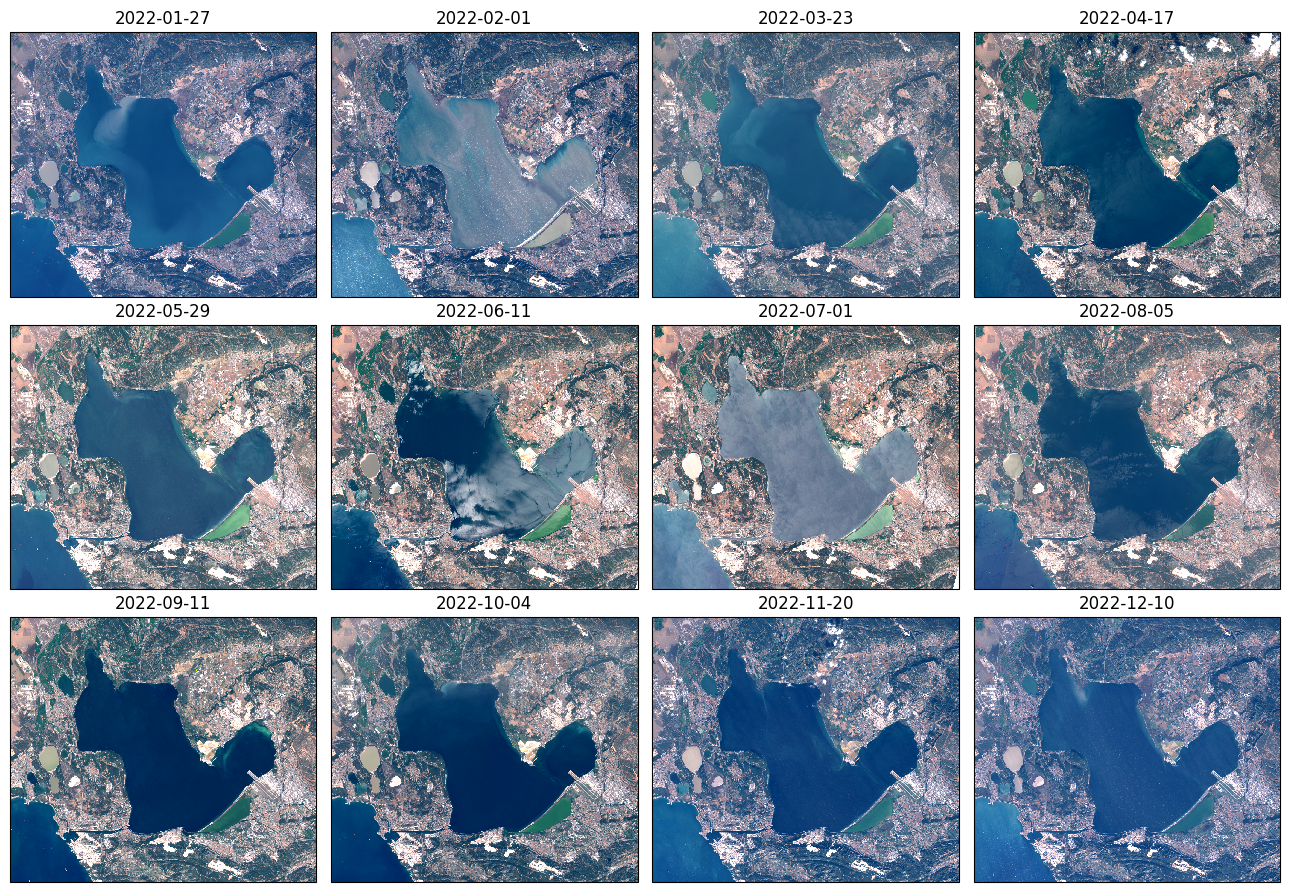

In [11]:
# int16 encoding: values can be slightly negative, clip before the square-root stretch
rgb = datacube.bands.sel(wl=[665, 560, 490]).clip(min=0) ** 0.5
fig = rgb.plot.imshow(col='time', col_wrap=4, rgb='wl', robust=True, size=3,
                      subplot_kws={'projection': proj}, transform=proj)
for ax, date in zip(fig.axs.flat, datacube.time.dt.strftime('%Y-%m-%d').values):
    ax.set_title(date)
plt.show()

Time series of the TOA reflectance in the middle of the lagoon:

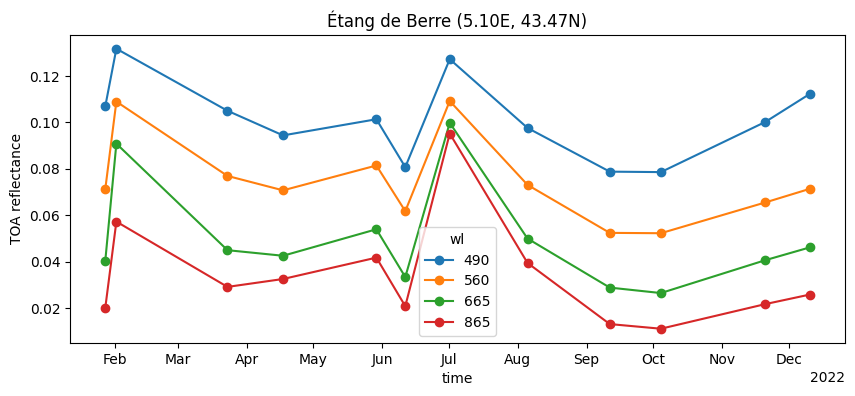

In [12]:
x, y = Transformer.from_crs(4326, datacube.rio.crs, always_xy=True).transform(5.10, 43.47)
pixel = datacube.bands.sel(x=x, y=y, method='nearest').sel(wl=[490, 560, 665, 865]).compute()

fig, ax = plt.subplots(figsize=(10, 4))
pixel.plot.line(x='time', hue='wl', marker='o', ax=ax)
ax.set_ylabel('TOA reflectance')
ax.set_title('Étang de Berre (5.10E, 43.47N)')
plt.show()

At the top of atmosphere, the signal includes the atmosphere and the sun glint. The peaks of
1 February and 1 July, in all the bands including the NIR, match the bright, grey lagoon of these
dates in the RGB above: most likely sun glint. GRS removes these contributions to retrieve the water
reflectance.

## Next steps

- Process the subsets with GRS to get the water reflectance.
- [Download](sentinel2_download.ipynb) the images of your own region and period.